<center>
    <p style="color: red; font-size: 20px;">Tên: Lê Thiên Hạo</p>
</center>
<center>
    <p style="color: red; font-size: 20px;">MSSV: 089206010393</p>
</center>

# K-Means Clustering — dùng thư viện scikit-learn

Bản này dùng `sklearn.cluster.KMeans` có sẵn thay vì tự cài đặt từng bước như notebook trước. Cùng bộ dữ liệu, cùng `k = 3`, nhưng toàn bộ vòng lặp centroid giờ chỉ gói gọn trong vài dòng code.

## Bước 1: Import thư viện

`pandas` dùng để tạo và thao tác `DataFrame` chứa dữ liệu.

In [1]:
import pandas as pd


## Bước 2: Tạo dữ liệu mẫu

Tạo `DataFrame` gồm 19 điểm dữ liệu 2 chiều (`x`, `y`) — giống hệt dữ liệu ở notebook cài đặt K-Means thủ công, để so sánh kết quả cho công bằng.

In [2]:
df = pd.DataFrame({
    'x': [12, 20, 28, 18, 29, 33, 24, 45, 45, 52, 51, 52, 55, 53, 55, 61, 64, 69, 72],
    'y': [39, 36, 30, 52, 54, 46, 55, 59, 63, 70, 66, 63, 58, 23, 14, 8, 19, 7, 24]
})

## Bước 3: Khởi tạo và fit mô hình KMeans

Toàn bộ phần "khởi tạo centroid ngẫu nhiên → assignment → update → lặp đến khi hội tụ" ở notebook trước giờ chỉ còn 2 dòng:
- `KMeans(n_clusters=3)`: tạo mô hình với `k = 3` cụm.
- `.fit(df)`: cho mô hình học trên dữ liệu — bên trong, sklearn tự chạy toàn bộ vòng lặp centroid tương tự như đã cài đặt thủ công ở bài trước.

In [3]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3)
kmeans.fit(df)


,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


## Bước 4: Lấy nhãn cụm và vị trí centroid

- `kmeans.predict(df)` → `labels`: cụm (0, 1 hoặc 2) mà mỗi điểm được gán vào.
- `kmeans.cluster_centers_`: toạ độ centroid cuối cùng (đã hội tụ) của từng cụm.

In [4]:
labels = kmeans.predict(df)
centroids = kmeans.cluster_centers_

## Bước 5: Import thư viện vẽ biểu đồ

`matplotlib.pyplot` dùng để trực quan hoá kết quả phân cụm.

In [5]:
import matplotlib.pyplot as plt

## Bước 6: Vẽ kết quả phân cụm

- `colmap` + `colors`: map mỗi label (0/1/2) sang một màu (cộng thêm 1 vì `colmap` đánh số từ 1, còn `labels` đánh số từ 0).
- Vẽ các điểm dữ liệu theo màu cụm, rồi vẽ centroid (lấy từ `kmeans.cluster_centers_`) đè lên trên — cho ra biểu đồ tương tự bước cuối ở bản cài đặt thủ công.

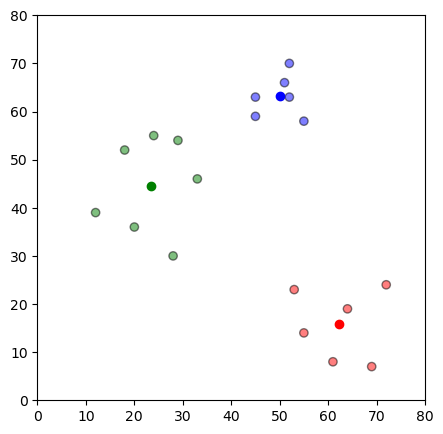

In [6]:
fig = plt.figure(figsize=(5, 5))

colmap = {1: 'r', 2: 'g', 3: 'b'}
colors = list(map(lambda x: colmap[x+1], labels))

plt.scatter(df['x'], df['y'], color=colors, alpha=0.5, edgecolor='k')
for idx, centroid in enumerate(centroids):
    plt.scatter(*centroid, color=colmap[idx+1])
plt.xlim(0, 80)
plt.ylim(0, 80)
plt.show()

## Tóm tắt

So với bản tự cài đặt, `sklearn.cluster.KMeans` gói gọn toàn bộ vòng lặp assignment/update thành 2 dòng: `KMeans(n_clusters=k).fit(df)`. Đây là lý do trong thực tế hầu như luôn dùng thư viện có sẵn — vừa nhanh vừa đã được tối ưu, thay vì tự cài lại thuật toán từ đầu.